# TPC rDCA, charge balance and drift QA — run by run

Read the compact `tpc_qa_summary.root` after `collect`. ROOT reads the histograms;
NumPy/pandas and Matplotlib make the selected comparisons, following the style of
the existing drift notebook. No event processing or Gaussian slice refitting is needed.

The main observables are the Gaussian-core means $\mu_+$ and $\mu_-$:

$$D_{\rm odd}=(\mu_+-\mu_-)/2,\qquad D_{\rm even}=(\mu_++\mu_-)/2.$$

Charge-odd rDCA is a useful distortion diagnostic. It is not uniquely a space-charge
measurement, and its ratio to a reference is not automatically a ratio of $k_{\rm eff}$.
Keep production settings, selections and reference conditions consistent.

In [1]:
# ============================================================
# Imports / ROOT style
# ============================================================
from pathlib import Path
import json
import math
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
import ROOT as root

root.gROOT.SetBatch(True)
root.TH1.AddDirectory(False)
root.gStyle.SetOptStat(0)
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["font.size"] = 13
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
print("ROOT:", root.gROOT.GetVersion())

Welcome to JupyROOT 6.30/06
ROOT: 6.30/06


In [2]:
# ============================================================
# Change paths / choose the comparisons here
# ============================================================
INPUT_FILE = Path("input/tpc_qa_summary.root")
# On your laptop: INPUT_FILE = Path("tpc_qa_summary.root")
GROUP = "run3pp/ana581_2026p005_v001"  # one production group at a time
REFERENCE_RUN = 79513
RUNS = None                           # None -> all available runs
PRIMARY_PT = "pt_0p5_1"
PT_WINDOWS = None                     # None -> all stored pT windows
SELECTED_RUNS = [79513, 79516, 79529]  # a few overlays, not 58 curves per panel
KINEMATIC_RUN = 79513                 # compare pT windows vs phi and eta here
RDCA_FAMILY = "auto"                  # auto / tpc_only / legacy

# Optional offline tables; leave None if unavailable.
CONDITIONS_CSV = None                 # Path("run_conditions.csv")
PHG_REFERENCE_CSV = None               # Path("phgarfield_references.csv")
GEM_COLUMN = "gem_current_uA"          # explicit units: no automatic current conversion
KEFF_COLUMN = "keff"                  # change to the actual column name if necessary
FIT_RESPONSE = False                 # optional descriptive straight-line fit, not a calibration

OUTPUT_DIR = Path("tpc_qa_plots")
SAVE_FIGURES = True
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SIDE_LABEL = {"south": "South", "north": "North"}
SIDE_NUMBER = {"south": 0, "north": 1}
COLORS = {"south": "tab:blue", "north": "tab:red"}

## Open the summary and identify what is actually available

New QA uses physical TPC sides and the added TPC-only selection. Legacy DCA plots
use **PCA-z sign**, despite the old north/south histogram names. They are not
physical-side selections. Legacy DCA is shown once with its original cuts; copying
it into several pT-window directories does not create pT-dependent measurements.

In [3]:
# ============================================================
# File / directory helpers
# ============================================================
if not INPUT_FILE.is_file():
    raise FileNotFoundError(f"Collect the completed batch first, then set INPUT_FILE: {INPUT_FILE}")
QA_FILE = root.TFile.Open(str(INPUT_FILE), "READ")
if not QA_FILE or QA_FILE.IsZombie() or QA_FILE.TestBit(root.TFile.kRecovered):
    raise RuntimeError(f"Cannot use ROOT file: {INPUT_FILE}")

def directories(directory):
    return sorted({k.GetName() for k in directory.GetListOfKeys()
                   if root.TClass.GetClass(k.GetClassName()).InheritsFrom("TDirectory")})

AVAILABLE_GROUPS = []
for system in directories(QA_FILE):
    if system == "metadata":
        continue
    for tag in directories(QA_FILE.GetDirectory(system)):
        AVAILABLE_GROUPS.append(f"{system}/{tag}")
print("Available production groups:", AVAILABLE_GROUPS)
if GROUP not in AVAILABLE_GROUPS:
    raise ValueError("Set GROUP to one of the production groups printed above")
group_dir = QA_FILE.GetDirectory(GROUP)
AVAILABLE_WINDOWS = [w for w in directories(group_dir) if w.startswith("pt_")]
if not AVAILABLE_WINDOWS:
    raise ValueError("No pT-window directories; use the production collect output")
PT_WINDOWS = AVAILABLE_WINDOWS if PT_WINDOWS is None else list(PT_WINDOWS)
if not set(PT_WINDOWS).issubset(AVAILABLE_WINDOWS):
    raise ValueError("Requested pT window is not in the file")
if PRIMARY_PT not in PT_WINDOWS:
    PRIMARY_PT = PT_WINDOWS[0]
run_dir = QA_FILE.GetDirectory(f"{GROUP}/{PRIMARY_PT}/runs")
AVAILABLE_RUNS = sorted(int(x) for x in directories(run_dir) if x.isdecimal())
AVAILABLE_RUNS = AVAILABLE_RUNS if RUNS is None else [r for r in AVAILABLE_RUNS if r in RUNS]
if not AVAILABLE_RUNS or REFERENCE_RUN not in AVAILABLE_RUNS:
    raise ValueError("The requested reference must be among the selected available runs")
SELECTED_RUNS = [r for r in SELECTED_RUNS if r in AVAILABLE_RUNS]
if not SELECTED_RUNS:
    SELECTED_RUNS = [AVAILABLE_RUNS[0]]
if KINEMATIC_RUN not in AVAILABLE_RUNS:
    KINEMATIC_RUN = SELECTED_RUNS[0]
RUN_INDEX = {r: i for i, r in enumerate(AVAILABLE_RUNS)}

if RDCA_FAMILY == "auto":
    RDCA_FAMILY = ("tpc_only" if any(QA_FILE.Get(f"{GROUP}/{w}/runs/{r}/rdca/tpc_only_south/rdca_charge_odd_vs_phi")
                    for w in PT_WINDOWS for r in AVAILABLE_RUNS) else "legacy")
if RDCA_FAMILY not in ("tpc_only", "legacy"):
    raise ValueError("RDCA_FAMILY must be auto, tpc_only or legacy")
DCA_WINDOWS = PT_WINDOWS if RDCA_FAMILY == "tpc_only" else [PRIMARY_PT]
POPULATIONS = ["south", "north"]

def population_name(population):
    if RDCA_FAMILY == "tpc_only":
        return "tpc_only_" + population
    return "legacy_pca_z_nonpositive" if population == "south" else "legacy_pca_z_positive"

def population_label(population):
    if RDCA_FAMILY == "tpc_only":
        return "TPC-only " + SIDE_LABEL[population]
    return "Legacy PCA-z <= 0" if population == "south" else "Legacy PCA-z > 0"

def pt_label(window):
    if RDCA_FAMILY == "legacy":
        return "legacy original selection (no added pT cut)"
    match = re.fullmatch(r"pt_([0-9p]+)_([0-9p]+)", window)
    return f"{match[1].replace('p', '.')} < pT < {match[2].replace('p', '.')} GeV/c" if match else window

def run_directory(run, window=PRIMARY_PT):
    return QA_FILE.GetDirectory(f"{GROUP}/{window}/runs/{run}")

def named_text(directory, path):
    obj = directory.Get(path) if directory else None
    return str(obj.GetTitle()) if obj else ""

print(f"{GROUP}: {len(AVAILABLE_RUNS)} runs; reference {REFERENCE_RUN}")
print("pT windows:", PT_WINDOWS)
print("DCA mode:", RDCA_FAMILY, "; selected overlays:", SELECTED_RUNS)
record_text = named_text(QA_FILE, "metadata/production_record_json")
PRODUCTION_RECORD = json.loads(record_text) if record_text else {}
if PRODUCTION_RECORD:
    settings = PRODUCTION_RECORD.get("batch", {}).get("settings", {})
    print("Recorded segment limit:", settings.get("max_files", "not recorded"))
    print("Failed/excluded runs:", len(PRODUCTION_RECORD.get("batch", {}).get("failed", [])))

Available production groups: ['run3pp/ana581_2026p005_v001']
run3pp/ana581_2026p005_v001: 58 runs; reference 79513
pT windows: ['pt_0p5_1', 'pt_1_2', 'pt_2_4']
DCA mode: legacy ; selected overlays: [79513, 79516, 79529]
Recorded segment limit: 10
Failed/excluded runs: 0


In [4]:
# ============================================================
# Read 1D profiles WITH validity masks; empty/failed bins stay NaN
# ============================================================
_CURVE_CACHE = {}

def curve(run, window, path):
    key = (run, window, path)
    if key in _CURVE_CACHE:
        return _CURVE_CACHE[key]
    directory = run_directory(run, window)
    h = directory.Get(path) if directory else None
    if not h or not h.InheritsFrom("TH1") or h.GetDimension() != 1:
        _CURVE_CACHE[key] = None
        return None
    mask_path = path + "_valid" if path.startswith("diagnostics/") else "diagnostics/" + path + "_valid"
    mask = directory.Get(mask_path)
    if not mask:
        warnings.warn(f"Skip profile without a validity mask: run {run}, {path}")
        _CURVE_CACHE[key] = None
        return None
    n = h.GetNbinsX()
    edges = np.array([h.GetXaxis().GetBinLowEdge(b) for b in range(1, n + 2)])
    y = np.array([h.GetBinContent(b) for b in range(1, n + 1)], float)
    ey = np.array([h.GetBinError(b) for b in range(1, n + 1)], float)
    valid = np.array([mask.GetBinContent(b) > 0 for b in range(1, n + 1)])
    valid &= np.isfinite(y) & np.isfinite(ey) & (ey >= 0)
    y[~valid] = np.nan
    ey[~valid] = np.nan
    result = dict(x=(edges[:-1] + edges[1:]) / 2, ex=np.diff(edges) / 2,
                  y=y, ey=ey, edges=edges, valid=valid)
    _CURVE_CACHE[key] = result
    return result

def dca_curve(run, window, population, axis="phi", component="odd"):
    name = f"rdca_charge_{component}_vs_{axis}" if component in ("odd", "even") else f"rdca_mean_vs_{axis}_{component}"
    return curve(run, window, f"rdca/{population_name(population)}/{name}")

def difference(current, reference, same_run=False):
    if current is None or reference is None:
        return None
    if current["edges"].shape != reference["edges"].shape or not np.allclose(current["edges"], reference["edges"], rtol=0, atol=1e-10):
        return None  # No interpolation across different physical bins.
    out = {k: v.copy() for k, v in current.items()}
    out["valid"] = current["valid"] & reference["valid"]
    out["y"] = current["y"] - reference["y"]
    out["ey"] = np.zeros_like(current["ey"]) if same_run else np.hypot(current["ey"], reference["ey"])
    out["y"][~out["valid"]] = np.nan
    out["ey"][~out["valid"]] = np.nan
    return out

def draw_curve(ax, data, label, **kwargs):
    if data is None or not np.any(data["valid"]):
        return False
    ax.errorbar(data["x"], data["y"], yerr=data["ey"], fmt="o-", ms=3, lw=1, capsize=1, label=label, **kwargs)
    return True

def finish(fig, name):
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=170, bbox_inches="tight")
        fig.savefig(OUTPUT_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)

def run_axis(ax):
    step = max(1, math.ceil(len(AVAILABLE_RUNS) / 12))
    ii = np.arange(0, len(AVAILABLE_RUNS), step)
    ax.set_xticks(ii, [str(AVAILABLE_RUNS[i]) for i in ii], rotation=60, ha="right")
    ax.set_xlim(-0.6, len(AVAILABLE_RUNS) - 0.4)
    ax.set_xlabel("Run (consecutive index; tick labels are run numbers)")

def legend_if_any(ax, **kwargs):
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(**kwargs)

## Selected charge-even / charge-odd profiles and reference changes

Use the stored Gaussian-slice means, not histogram means of the full DCA tails.
The reference is plotted as itself with zero self-difference. Different-run errors
are propagated as independent samples; different differences share reference uncertainty.

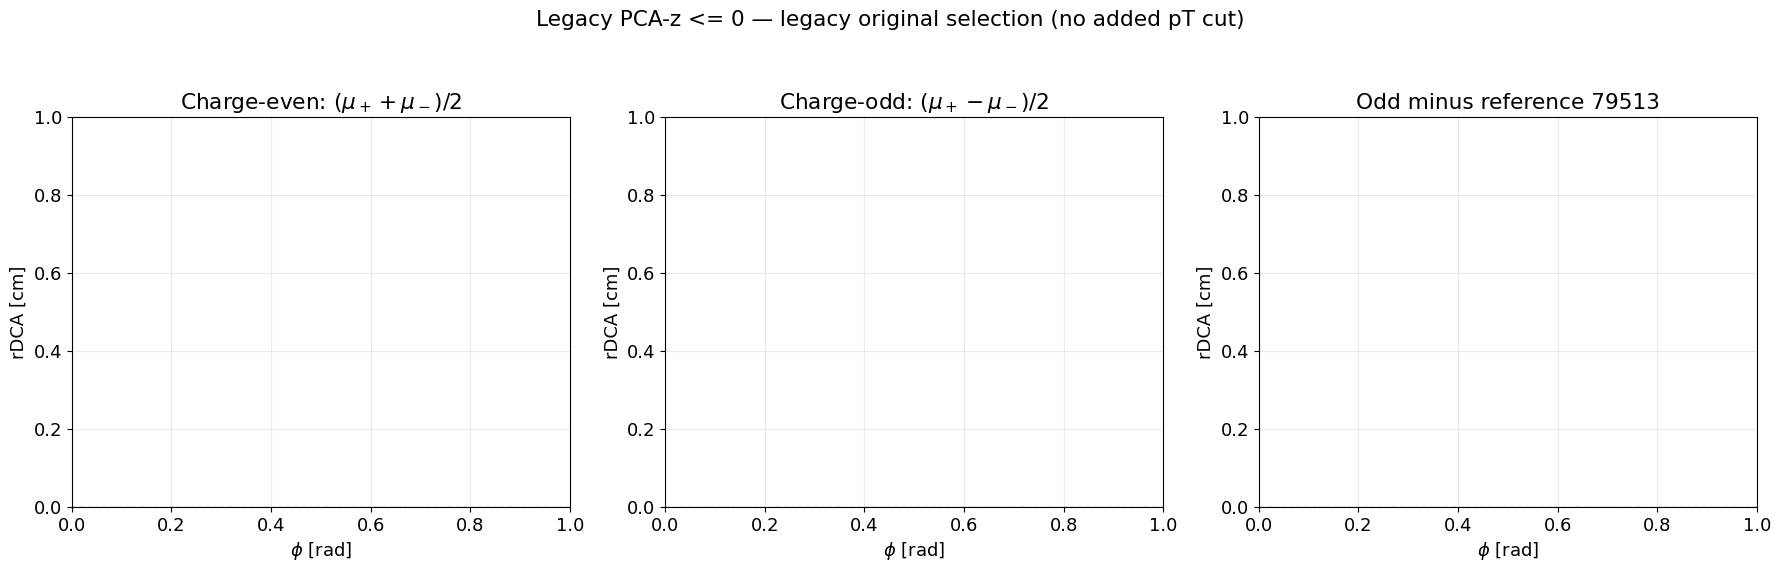

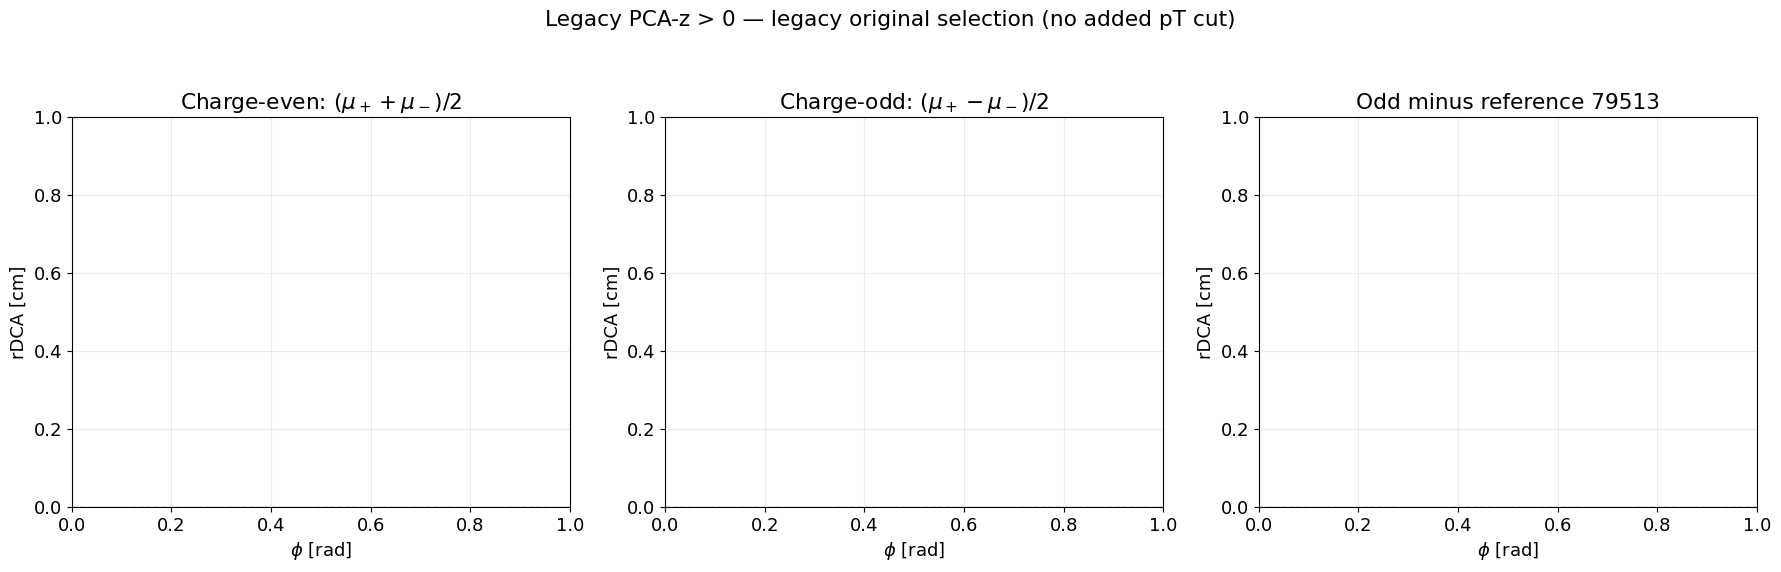

In [5]:
# ============================================================
# A few runs: half-sum, half-difference, and odd change from reference
# ============================================================
for population in POPULATIONS:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    reference = dca_curve(REFERENCE_RUN, PRIMARY_PT, population, component="odd")
    for run in SELECTED_RUNS:
        for ax, component in zip(axes[:2], ("even", "odd")):
            draw_curve(ax, dca_curve(run, PRIMARY_PT, population, component=component), str(run))
        odd = dca_curve(run, PRIMARY_PT, population, component="odd")
        draw_curve(axes[2], difference(odd, reference, run == REFERENCE_RUN), str(run))
    for ax, title in zip(axes, (r"Charge-even: $(\mu_+ + \mu_-)/2$", r"Charge-odd: $(\mu_+ - \mu_-)/2$", f"Odd minus reference {REFERENCE_RUN}")):
        ax.axhline(0, color="gray", ls="--", lw=1)
        ax.set(xlabel=r"$\phi$ [rad]", ylabel="rDCA [cm]", title=title)
        legend_if_any(ax, fontsize=9)
    fig.suptitle(f"{population_label(population)} — {pt_label(PRIMARY_PT)}", y=1.04)
    finish(fig, f"rdca_selected_{population}")

## All runs at once

Rows are runs and columns are phi bins. White cells are unavailable/failed fits;
no zero is substituted. This is more readable than 58 overlaid curves.

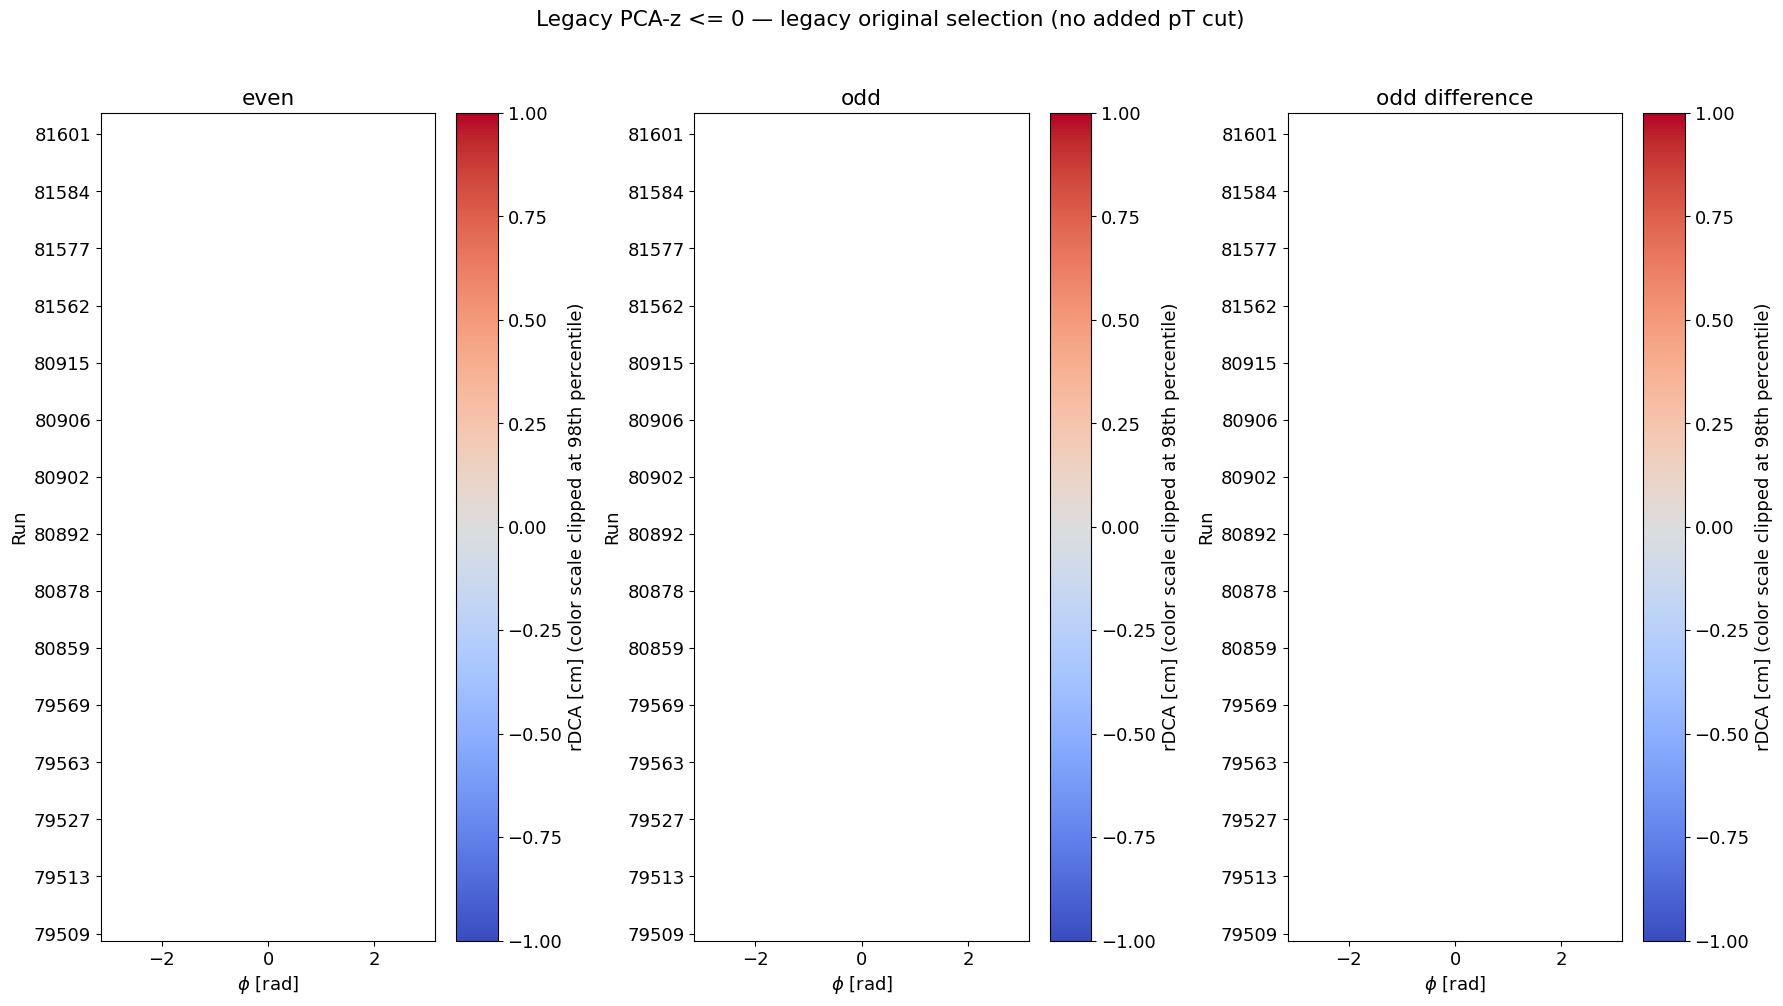

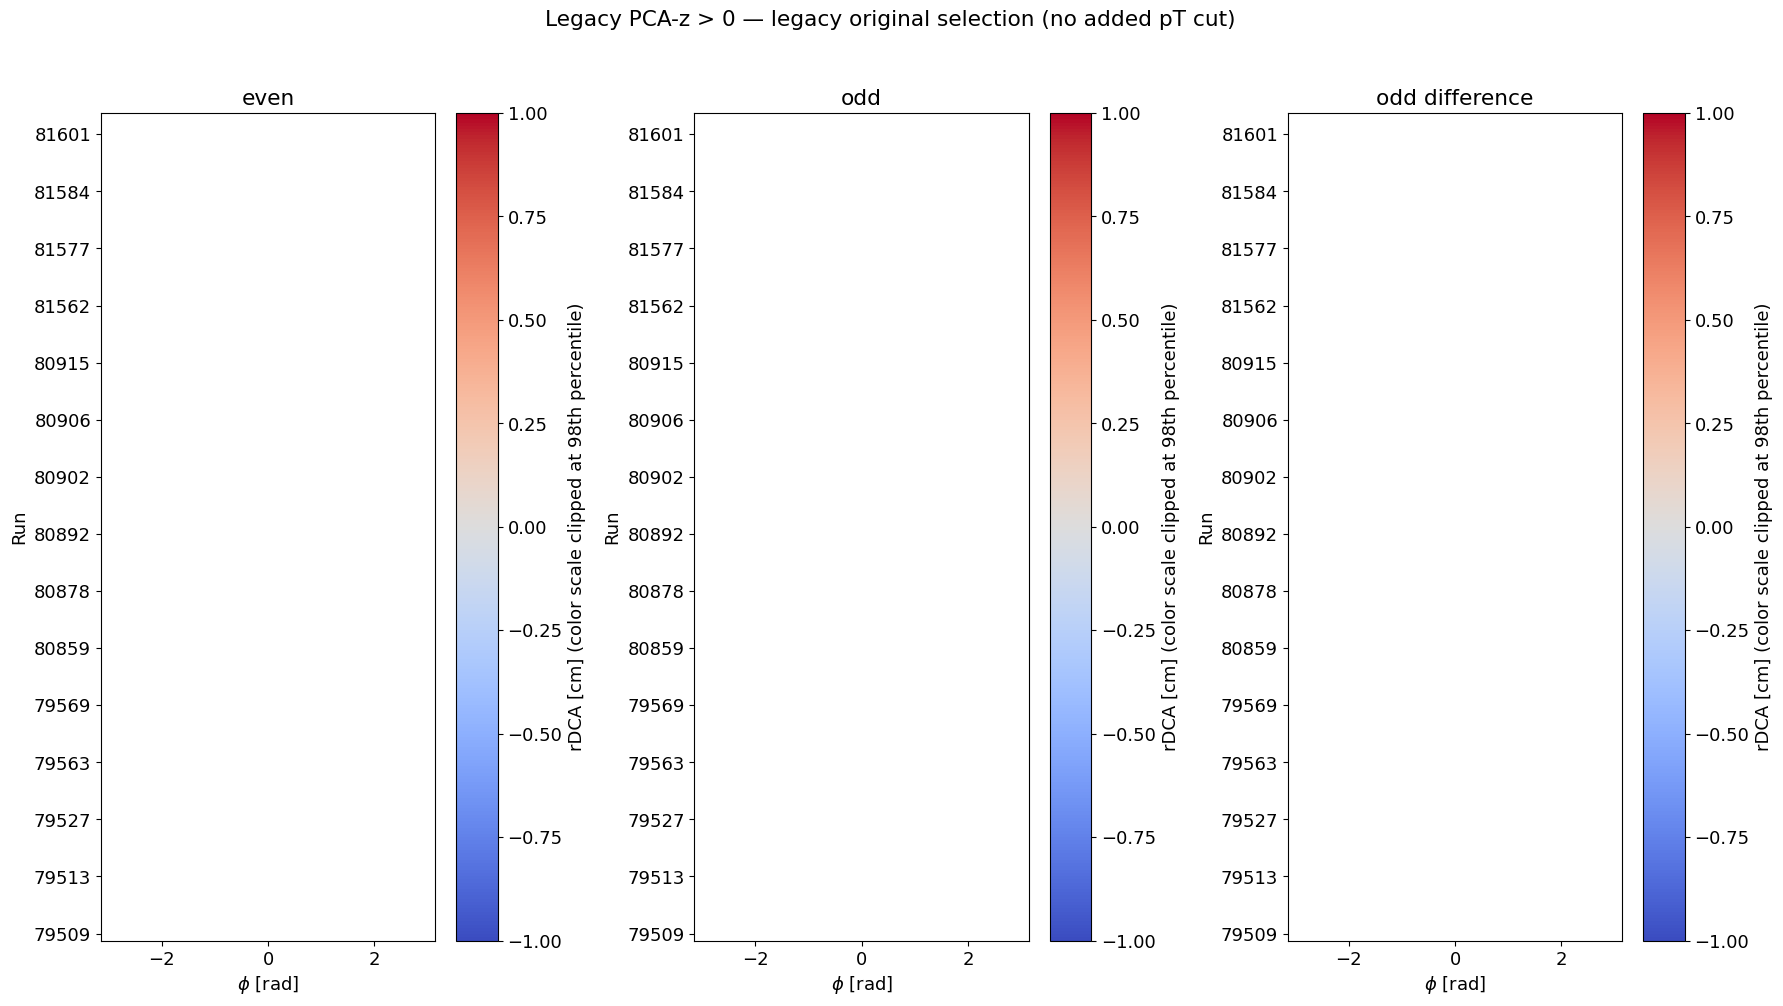

In [6]:
# ============================================================
# All-run phi maps
# ============================================================
for population in POPULATIONS:
    ref = dca_curve(REFERENCE_RUN, PRIMARY_PT, population)
    if ref is None:
        print("No reference phi profile:", population_label(population))
        continue
    fig, axes = plt.subplots(1, 3, figsize=(18, max(6, min(13, len(AVAILABLE_RUNS) * .17))))
    for ax, component in zip(axes, ("even", "odd", "odd_difference")):
        rows = []
        for run in AVAILABLE_RUNS:
            c = dca_curve(run, PRIMARY_PT, population, component="even" if component == "even" else "odd")
            if component == "odd_difference":
                c = difference(c, ref, run == REFERENCE_RUN)
            aligned = c is not None and c["edges"].shape == ref["edges"].shape and np.allclose(c["edges"], ref["edges"], rtol=0, atol=1e-10)
            rows.append(c["y"] if aligned else np.full(len(ref["x"]), np.nan))
        values = np.asarray(rows)
        finite = np.abs(values[np.isfinite(values)])
        limit = max(.001, np.quantile(finite, .98)) if len(finite) else 1.
        image = ax.pcolormesh(ref["edges"], np.arange(len(AVAILABLE_RUNS) + 1) - .5,
                              np.ma.masked_invalid(values), cmap="coolwarm", vmin=-limit, vmax=limit, shading="flat")
        step = max(1, math.ceil(len(AVAILABLE_RUNS) / 18))
        ii = np.arange(0, len(AVAILABLE_RUNS), step)
        ax.set_yticks(ii, [str(AVAILABLE_RUNS[i]) for i in ii])
        ax.set(xlabel=r"$\phi$ [rad]", ylabel="Run", title=component.replace("_", " "))
        ax.grid(False)
        fig.colorbar(image, ax=ax, label="rDCA [cm] (color scale clipped at 98th percentile)")
    fig.suptitle(f"{population_label(population)} — {pt_label(PRIMARY_PT)}", y=1.02)
    finish(fig, f"rdca_all_runs_{population}")

## Small run-summary observables

For each charge combination fit/read
$D(\phi)=a_0+a_1\sin\phi+a_2\cos\phi+a_3\sin2\phi+a_4\cos2\phi$.
The signed sine/cosine coefficients preserve the distortion phase; an average
over phi alone can cancel a large distortion. Stored accepted ROOT fits are used
first. A missing fit can be recomputed from valid 1D Gaussian means when there
are at least eight points, positive errors and a full-rank design matrix.
No failed slice is converted into a point.

In [7]:
# ============================================================
# Harmonic coefficients, errors and fit quality
# ============================================================
PARAMETERS = ["offset", "sin1", "cos1", "sin2", "cos2"]
_FIT_CACHE = {}

def harmonic_fit(run, window, population, component):
    key = (run, window, population, component)
    if key in _FIT_CACHE:
        return _FIT_CACHE[key]
    c = dca_curve(run, window, population, component=component)
    if c is None or np.count_nonzero(c["valid"]) < 8:
        _FIT_CACHE[key] = None
        return None
    path = f"diagnostics/rdca/{population_name(population)}/calibration_fits/rdca_charge_{component}_vs_phi_harmonic_result"
    stored = run_directory(run, window).Get(path)
    if stored and stored.InheritsFrom("TFitResult") and stored.Status() == 0 and stored.CovMatrixStatus() >= 2 and stored.NPar() == 5:
        result = dict(value=np.array([stored.Parameter(i) for i in range(5)]),
                      covariance=np.array([[stored.CovMatrix(i, j) for j in range(5)] for i in range(5)]),
                      chi2_ndf=stored.Chi2() / stored.Ndf() if stored.Ndf() > 0 else np.nan,
                      source="stored ROOT fit", npoints=int(np.count_nonzero(c["valid"])))
    else:
        valid = c["valid"] & (c["ey"] > 0)
        if np.count_nonzero(valid) < 8:
            _FIT_CACHE[key] = None
            return None
        x, y, error = c["x"][valid], c["y"][valid], c["ey"][valid]
        design = np.column_stack([np.ones(len(x)), np.sin(x), np.cos(x), np.sin(2*x), np.cos(2*x)])
        weighted = design / error[:, None]
        if np.linalg.matrix_rank(weighted) < 5:
            _FIT_CACHE[key] = None
            return None
        values = np.linalg.lstsq(weighted, y / error, rcond=None)[0]
        covariance = np.linalg.inv(weighted.T @ weighted)
        result = dict(value=values, covariance=covariance,
                      chi2_ndf=float(np.sum(((y-design@values)/error)**2)/(len(x)-5)),
                      source="weighted fit of valid Gaussian means", npoints=len(x))
    if not np.all(np.isfinite(result["value"])) or not np.all(np.isfinite(result["covariance"])) or np.any(np.diag(result["covariance"]) < 0):
        result = None
    _FIT_CACHE[key] = result
    return result

fit_rows = []
for window in DCA_WINDOWS:
    for run in AVAILABLE_RUNS:
        for population in POPULATIONS:
            row = dict(run=run, window=window, selection=pt_label(window), population=population_label(population), population_key=population)
            for component in ("odd", "even"):
                fit = harmonic_fit(run, window, population, component)
                row[f"{component}_fit_source"] = fit["source"] if fit else "unavailable"
                row[f"{component}_chi2_ndf"] = fit["chi2_ndf"] if fit else np.nan
                row[f"{component}_valid_phi_bins"] = fit["npoints"] if fit else 0
                for i, parameter in enumerate(PARAMETERS):
                    row[f"{component}_{parameter}_cm"] = fit["value"][i] if fit else np.nan
                    row[f"{component}_{parameter}_error_cm"] = np.sqrt(max(0., fit["covariance"][i,i])) if fit else np.nan
            fit_rows.append(row)
FIT_SUMMARY = pd.DataFrame(fit_rows)
display(FIT_SUMMARY.head(8))

,run,window,selection,population,population_key,odd_fit_source,odd_chi2_ndf,odd_valid_phi_bins,odd_offset_cm,odd_offset_error_cm,...,even_offset_cm,even_offset_error_cm,even_sin1_cm,even_sin1_error_cm,even_cos1_cm,even_cos1_error_cm,even_sin2_cm,even_sin2_error_cm,even_cos2_cm,even_cos2_error_cm
0,79509,pt_0p5_1,legacy original selection (no added pT cut),Legacy PCA-z <= 0,south,unavailable,NaN,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,79509,pt_0p5_1,legacy original selection (no added pT cut),Legacy PCA-z > 0,north,unavailable,NaN,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,79510,pt_0p5_1,legacy original selection (no added pT cut),Legacy PCA-z <= 0,south,unavailable,NaN,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,79510,pt_0p5_1,legacy original selection (no added pT cut),Legacy PCA-z > 0,north,unavailable,NaN,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,79511,pt_0p5_1,legacy original selection (no added pT cut),Legacy PCA-z <= 0,south,unavailable,NaN,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,79511,pt_0p5_1,legacy original selection (no added pT cut),Legacy PCA-z > 0,north,unavailable,NaN,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,79512,pt_0p5_1,legacy original selection (no added pT cut),Legacy PCA-z <= 0,south,unavailable,NaN,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,79512,pt_0p5_1,legacy original selection (no added pT cut),Legacy PCA-z > 0,north,unavailable,NaN,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


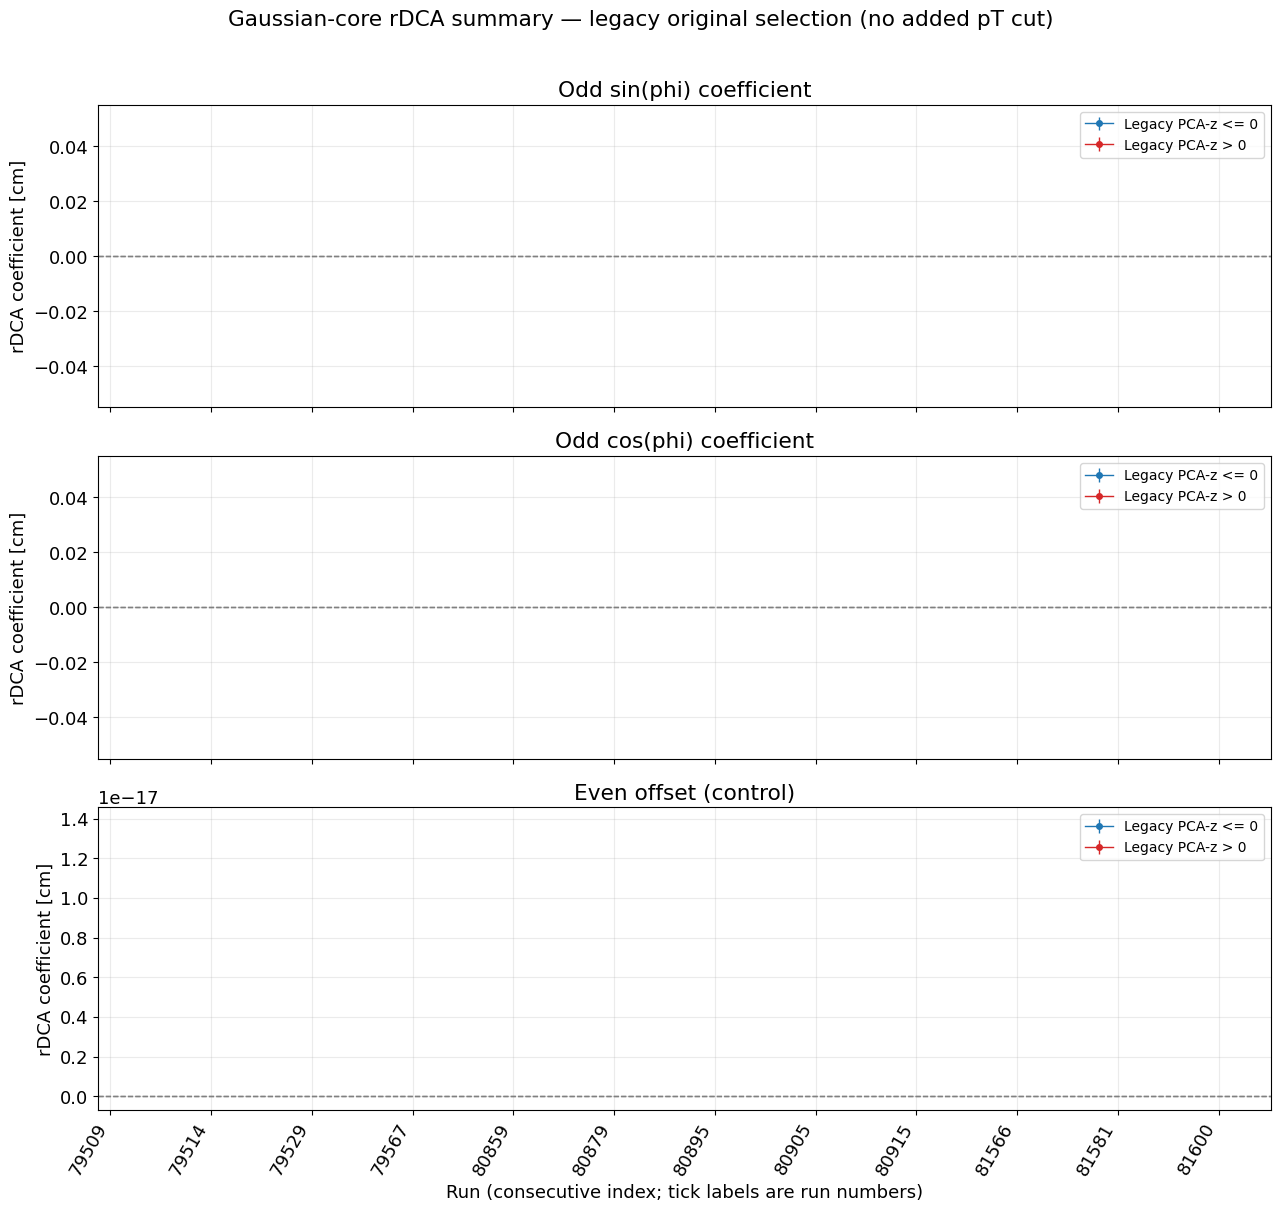

In [8]:
# ============================================================
# All runs: signed odd first harmonics and an even control
# ============================================================
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for population in POPULATIONS:
    table = FIT_SUMMARY[(FIT_SUMMARY.window == PRIMARY_PT) & (FIT_SUMMARY.population_key == population)]
    for ax, metric, title in zip(axes, ("odd_sin1", "odd_cos1", "even_offset"),
                                ("Odd sin(phi) coefficient", "Odd cos(phi) coefficient", "Even offset (control)")):
        good = np.isfinite(table[f"{metric}_cm"])
        data = table[good]
        ax.errorbar([RUN_INDEX[r] for r in data.run], data[f"{metric}_cm"], yerr=data[f"{metric}_error_cm"],
                    fmt="o-", ms=4, lw=1, color=COLORS[population], label=population_label(population))
        ax.set(ylabel="rDCA coefficient [cm]", title=title)
        ax.axhline(0, color="gray", ls="--", lw=1)
        legend_if_any(ax, fontsize=10)
run_axis(axes[-1])
fig.suptitle(f"Gaussian-core rDCA summary — {pt_label(PRIMARY_PT)}", y=1.01)
finish(fig, "rdca_harmonics_all_runs")

## Dependence on pT, eta and signed q/pT

These cells require the new TPC-only QA. They explicitly skip legacy-only input,
which has no recoverable pT-resolved DCA-versus-eta information.

In [9]:
# ============================================================
# One selected run: pT windows vs phi / eta
# ============================================================
if RDCA_FAMILY != "tpc_only":
    print("Skipped pT/eta DCA panels: legacy QA does not store these observables.")
else:
    for axis, xlabel in (("phi", r"$\phi$ [rad]"), ("eta", r"$\eta$")):
        fig, axes = plt.subplots(2, 2, figsize=(13, 10))
        plotted = 0
        for i, population in enumerate(POPULATIONS):
            for j, component in enumerate(("even", "odd")):
                ax = axes[i,j]
                for window in PT_WINDOWS:
                    plotted += draw_curve(ax, dca_curve(KINEMATIC_RUN, window, population, axis, component), pt_label(window))
                ax.set(xlabel=xlabel, ylabel="rDCA [cm]", title=f"{population_label(population)} / {component}")
                ax.axhline(0, color="gray", ls="--", lw=1)
                legend_if_any(ax, fontsize=9)
        if plotted:
            fig.suptitle(f"Run {KINEMATIC_RUN}: Gaussian rDCA vs {axis} in pT windows", y=1.02)
            finish(fig, f"rdca_{axis}_pt_windows_run{KINEMATIC_RUN}")
        else:
            plt.close(fig)
            print("No valid", axis, "profiles for run", KINEMATIC_RUN)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    plotted = 0
    for ax, population in zip(axes, POPULATIONS):
        for color_index, run in enumerate(SELECTED_RUNS):
            c = curve(run, PRIMARY_PT, f"rdca/{population_name(population)}/rdca_mean_vs_qoverpt")
            # q/pT bins already select momentum; the parent pT directory adds no cut here.
            if c is not None:
                for sign in (-1, 1):
                    sub = {k: v.copy() for k,v in c.items()}
                    valid = sub["valid"] & (sign*sub["x"] > 0)
                    sub["valid"] = valid
                    sub["y"][~valid] = np.nan
                    sub["ey"][~valid] = np.nan
                    plotted += draw_curve(ax, sub, str(run) if sign < 0 else None, color=f"C{color_index % 10}")
        ax.set(xlabel="q/pT [c/GeV]", ylabel="Gaussian rDCA [cm]", title=population_label(population))
        ax.axhline(0, color="gray", ls="--", lw=1)
        legend_if_any(ax)
    if plotted:
        fig.suptitle("Signed q/pT profiles — native q/pT selection, no extra pT-window cut", y=1.02)
        finish(fig, "rdca_signed_qoverpt")
    else:
        plt.close(fig)
        print("No signed q/pT profiles stored")

Skipped pT/eta DCA panels: legacy QA does not store these observables.


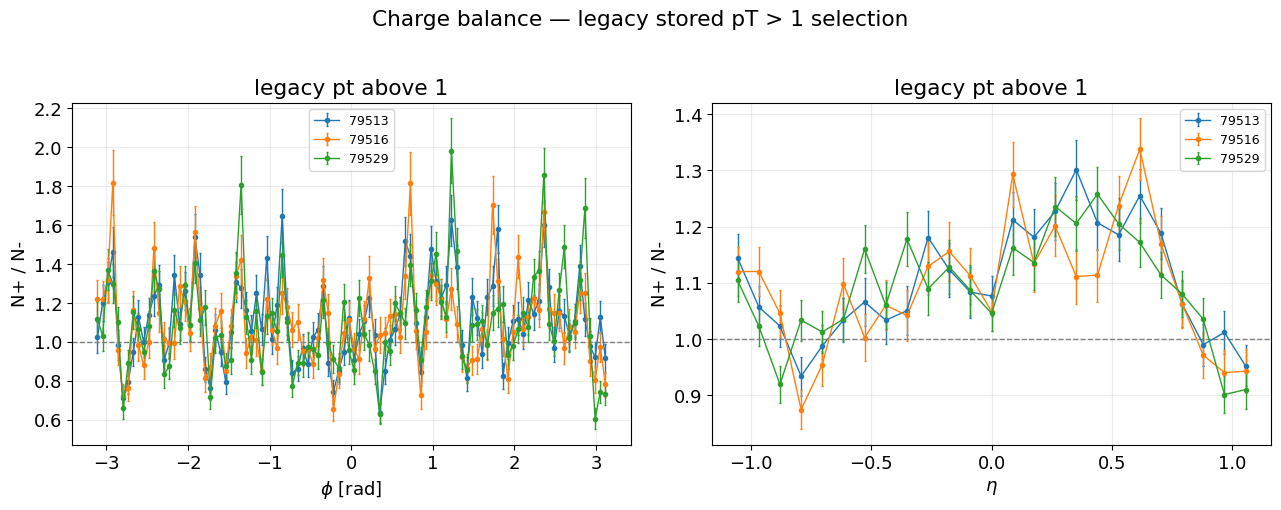

In [10]:
# ============================================================
# Charge balance N+/N- versus phi and eta
# ============================================================
charge_selection = [population_name(p) for p in POPULATIONS] if RDCA_FAMILY == "tpc_only" else ["legacy_pt_above_1"]
fig, axes = plt.subplots(len(charge_selection), 2, figsize=(13, 5*len(charge_selection)), squeeze=False)
plotted = 0
for i, selection in enumerate(charge_selection):
    for j, axis in enumerate(("phi", "eta")):
        ax = axes[i,j]
        for run in SELECTED_RUNS:
            c = curve(run, PRIMARY_PT, f"charge/{selection}/charge_ratio_vs_{axis}")
            plotted += draw_curve(ax, c, str(run))
        ax.set(xlabel=r"$\phi$ [rad]" if axis == "phi" else r"$\eta$", ylabel="N+ / N-", title=selection.replace("_", " "))
        ax.axhline(1, color="gray", ls="--", lw=1)
        legend_if_any(ax, fontsize=9)
if plotted:
    fig.suptitle("Charge balance — " + (pt_label(PRIMARY_PT) if RDCA_FAMILY == "tpc_only" else "legacy stored pT > 1 selection"), y=1.02)
    finish(fig, "charge_balance_phi_eta")
else:
    plt.close(fig)
    print("No supported charge-balance profiles stored")

## Run conditions: do we have GEM current or k_eff?

The standard QA histograms do **not** encode these values. The processing command
used so far did not pass a conditions CSV, so they are expected to be missing.
This cell checks embedded `run_conditions_json` and optionally joins an offline CSV.
No GEM current or k_eff is inferred from rDCA.

Optional table columns: `group,run,side,gem_current_uA,keff`.
`side` can be blank/`all` for a run-level value, or `south`/`north` (`0`/`1`).
Current units must match the column name. Supply run averages appropriate to the
selected segments; the first ten segments need not represent the whole run.
A side-specific current is never assigned to a legacy PCA-z population.
The notebook writes a blank template only when it does not already exist.

In [11]:
# ============================================================
# Read actual recorded conditions / optional external CSV
# ============================================================
def finite_number(value):
    try:
        number = float(value)
        return number if np.isfinite(number) else np.nan
    except (ValueError, TypeError):
        return np.nan

def normalize_side(value):
    key = str(value).strip().lower() if value is not None else ""
    mapping = {"": "all", "nan": "all", "all": "all", "0": "south", "0.0": "south", "south": "south", "s": "south", "1": "north", "1.0": "north", "north": "north", "n": "north"}
    if key not in mapping:
        raise ValueError(f"Unknown conditions side: {value}")
    return mapping[key]

raw_conditions = []
for run in AVAILABLE_RUNS:
    text = named_text(run_directory(run), "metadata/analysis/run_conditions_json")
    if text:
        for item in json.loads(text):
            label = item.get("run", item.get("label", run))
            if str(label) in (str(run), f"{run:08d}"):
                raw_conditions.append(dict(item, run=run, _source="embedded conditions"))
if CONDITIONS_CSV is not None:
    with Path(CONDITIONS_CSV).open() as stream:
        import csv
        raw_conditions.extend(dict(row, _source=str(CONDITIONS_CSV)) for row in csv.DictReader(stream))

condition_values = {}
for item in raw_conditions:
    if item.get("group", GROUP) not in ("", GROUP):
        continue
    run_value = finite_number(item.get("run", item.get("label")))
    if not np.isfinite(run_value) or int(run_value) not in AVAILABLE_RUNS:
        continue
    run, side = int(run_value), normalize_side(item.get("side", "all"))
    for field in (GEM_COLUMN, KEFF_COLUMN):
        value = finite_number(item.get(field))
        if not np.isfinite(value):
            continue
        key = (run, side, field)
        if key in condition_values and not np.isclose(condition_values[key][0], value, rtol=1e-10, atol=1e-12):
            raise ValueError(f"Conflicting conditions for {key}; resolve the input tables")
        condition_values[key] = (value, item.get("_source", "table"))

def condition(run, population, field):
    # Legacy PCA-z groups cannot be matched to one physical TPC side.
    keys = [(run, "all", field)] if RDCA_FAMILY == "legacy" else [(run, population, field), (run, "all", field)]
    for key in keys:
        if key in condition_values:
            return condition_values[key][0]
    return np.nan

CONDITIONS_AVAILABLE = pd.DataFrame([
    dict(run=r, population=population_label(p), gem_current=condition(r,p,GEM_COLUMN), keff=condition(r,p,KEFF_COLUMN))
    for r in AVAILABLE_RUNS for p in POPULATIONS])
print("Recorded conditions columns:", sorted({key for row in raw_conditions for key in row if not key.startswith("_")}))
for column in ("gem_current", "keff"):
    count = CONDITIONS_AVAILABLE.loc[np.isfinite(CONDITIONS_AVAILABLE[column]), "run"].nunique()
    print(f"{column}: {count}/{len(AVAILABLE_RUNS)} runs with usable values")
display(CONDITIONS_AVAILABLE.head(8))
template = OUTPUT_DIR / "run_conditions_template.csv"
if not template.exists():
    pd.DataFrame({"group": GROUP, "run": AVAILABLE_RUNS, "side": "all", GEM_COLUMN: "", KEFF_COLUMN: ""}).to_csv(template,index=False)
print("Optional conditions template:", template)

Recorded conditions columns: []
gem_current: 0/58 runs with usable values
keff: 0/58 runs with usable values


,run,population,gem_current,keff
0,79509,Legacy PCA-z <= 0,NaN,NaN
1,79509,Legacy PCA-z > 0,NaN,NaN
2,79510,Legacy PCA-z <= 0,NaN,NaN
3,79510,Legacy PCA-z > 0,NaN,NaN
4,79511,Legacy PCA-z <= 0,NaN,NaN
5,79511,Legacy PCA-z > 0,NaN,NaN
6,79512,Legacy PCA-z <= 0,NaN,NaN
7,79512,Legacy PCA-z > 0,NaN,NaN


Optional conditions template: tpc_qa_plots/run_conditions_template.csv


## Timing and PHGarfield comparison

Measured t0 and CM are timing-edge midpoints in **unpacked time bins**. The raw
presample/unpacker shift was already applied by the postprocessor. It is not
subtracted again here. Configured PHGarfield t0 is a model input, not a fitted edge.

Baseline velocity priority is: optional external PHGarfield reference CSV,
embedded supplied reference, native equal-FEE PHGarfield baseline. These sources
are labeled; a changed source between runs is reported. Hit-weighted and z-edge
velocities are different observables and are not silently mixed with the baseline.
Missing predictions stay missing. Drift-edge uncertainties are not estimated.

In [12]:
# ============================================================
# Side scalar helper / optional offline PHGarfield reference table
# ============================================================
def scalar(run, name, side):
    c = curve(run, PRIMARY_PT, "drift/" + name)
    if c is None:
        return np.nan
    b = np.flatnonzero(c["valid"] & np.isclose(c["x"], SIDE_NUMBER[side]))
    return float(c["y"][b[0]]) if len(b) else np.nan

phg_table = {}
if PHG_REFERENCE_CSV is not None:
    import csv
    with Path(PHG_REFERENCE_CSV).open() as stream:
        for row in csv.DictReader(stream):
            if row.get("group", GROUP) not in ("", GROUP):
                continue
            run_value = finite_number(row.get("run", row.get("label")))
            if not np.isfinite(run_value) or int(run_value) not in AVAILABLE_RUNS:
                continue
            side = normalize_side(row.get("side"))
            if side == "all":
                raise ValueError("PHGarfield references need an explicit physical side")
            key = int(run_value), side
            if key in phg_table:
                raise ValueError(f"Duplicate PHGarfield reference {key}")
            phg_table[key] = row

drift_rows = []
for run in AVAILABLE_RUNS:
    for side in ("south", "north"):
        row = dict(run=run, side=side,
                   t0_bins=scalar(run,"t0_vs_side",side),
                   cm_bins=scalar(run,"cm_time_vs_side",side),
                   v_data_cm_us=scalar(run,"drift_velocity_data_vs_side",side),
                   configured_t0_bins=scalar(run,"t0_phgarfield_configured_vs_side",side),
                   v_phg_cm_us=np.nan, phg_source="missing", comparison_compatible=True)
        if not np.isfinite(row["configured_t0_bins"]):
            sums = run_directory(run).Get("metadata/drift_calibration_sums")
            if sums and sums.InheritsFrom("TH1") and sums.GetNbinsX() >= 8 and sums.GetBinContent(1) > 0:
                value = sums.GetBinContent(8) / sums.GetBinContent(1)
                if np.isfinite(value):
                    row["configured_t0_bins"] = value
        external = phg_table.get((run,side))
        supplied = scalar(run,"drift_velocity_phgarfield_reference_vs_side",side)
        native = scalar(run,"drift_velocity_phgarfield_baseline_vs_side",side)
        if external is not None:
            value = finite_number(external.get("velocity_cm_us"))
            if np.isfinite(value) and value <= 0:
                raise ValueError("PHGarfield velocity must be positive")
            row["v_phg_cm_us"] = value
            row["configured_t0_bins"] = finite_number(external.get("t0_bins"))
            row["phg_source"] = "external baseline: " + external.get("source", "unspecified")
            text = named_text(run_directory(run), "metadata/drift_convention")
            # Reject known geometry/clock mismatches in an offline join.
            for field, token in (("time_bin_ns","dt"),("z_pad_cm","z_pad"),("cm_halfwidth_cm","CM_half")):
                value = finite_number(external.get(field))
                match = re.search(re.escape(token) + r"=([0-9.eE+-]+)", text)
                if np.isfinite(value) and match and not np.isclose(value,float(match[1]),rtol=0,atol=1e-5):
                    row["comparison_compatible"] = False
        elif np.isfinite(supplied):
            row["v_phg_cm_us"] = supplied
            row["phg_source"] = "embedded supplied PHGarfield baseline"
        elif np.isfinite(native):
            row["v_phg_cm_us"] = native
            row["phg_source"] = "native equal-FEE PHGarfield baseline"
        row["data_over_phg"] = (row["v_data_cm_us"]/row["v_phg_cm_us"]
                                if row["comparison_compatible"] and np.isfinite(row["v_phg_cm_us"]) and row["v_phg_cm_us"]>0 else np.nan)
        drift_rows.append(row)
DRIFT_SUMMARY = pd.DataFrame(drift_rows)
print("PHGarfield source coverage:")
display(DRIFT_SUMMARY.groupby("phg_source").size().rename("side/run entries").to_frame())
if not np.isfinite(DRIFT_SUMMARY.v_phg_cm_us).any():
    print("No PHGarfield baseline stored. Export predictions on SDCC, then set PHG_REFERENCE_CSV; no QA reprocessing is needed for an offline join.")
if not DRIFT_SUMMARY.comparison_compatible.all():
    print("Known clock/geometry mismatch: affected data/PHGarfield ratios are suppressed.")
display(DRIFT_SUMMARY.head(8))

PHGarfield source coverage:


,side/run entries
phg_source,
missing,116


No PHGarfield baseline stored. Export predictions on SDCC, then set PHG_REFERENCE_CSV; no QA reprocessing is needed for an offline join.


,run,side,t0_bins,cm_bins,v_data_cm_us,configured_t0_bins,v_phg_cm_us,phg_source,comparison_compatible,data_over_phg
0,79509,south,7.086922,250.314966,7.406615,NaN,NaN,missing,True,NaN
1,79509,north,7.392092,250.527713,7.409430,NaN,NaN,missing,True,NaN
2,79510,south,7.579327,250.179857,7.425773,NaN,NaN,missing,True,NaN
3,79510,north,7.740996,250.383573,7.424486,NaN,NaN,missing,True,NaN
4,79511,south,7.542508,250.223401,7.423314,NaN,NaN,missing,True,NaN
5,79511,north,7.655813,250.364245,7.422472,NaN,NaN,missing,True,NaN
6,79512,south,7.479943,250.505767,7.412778,NaN,NaN,missing,True,NaN
7,79512,north,7.690895,250.694656,7.413451,NaN,NaN,missing,True,NaN


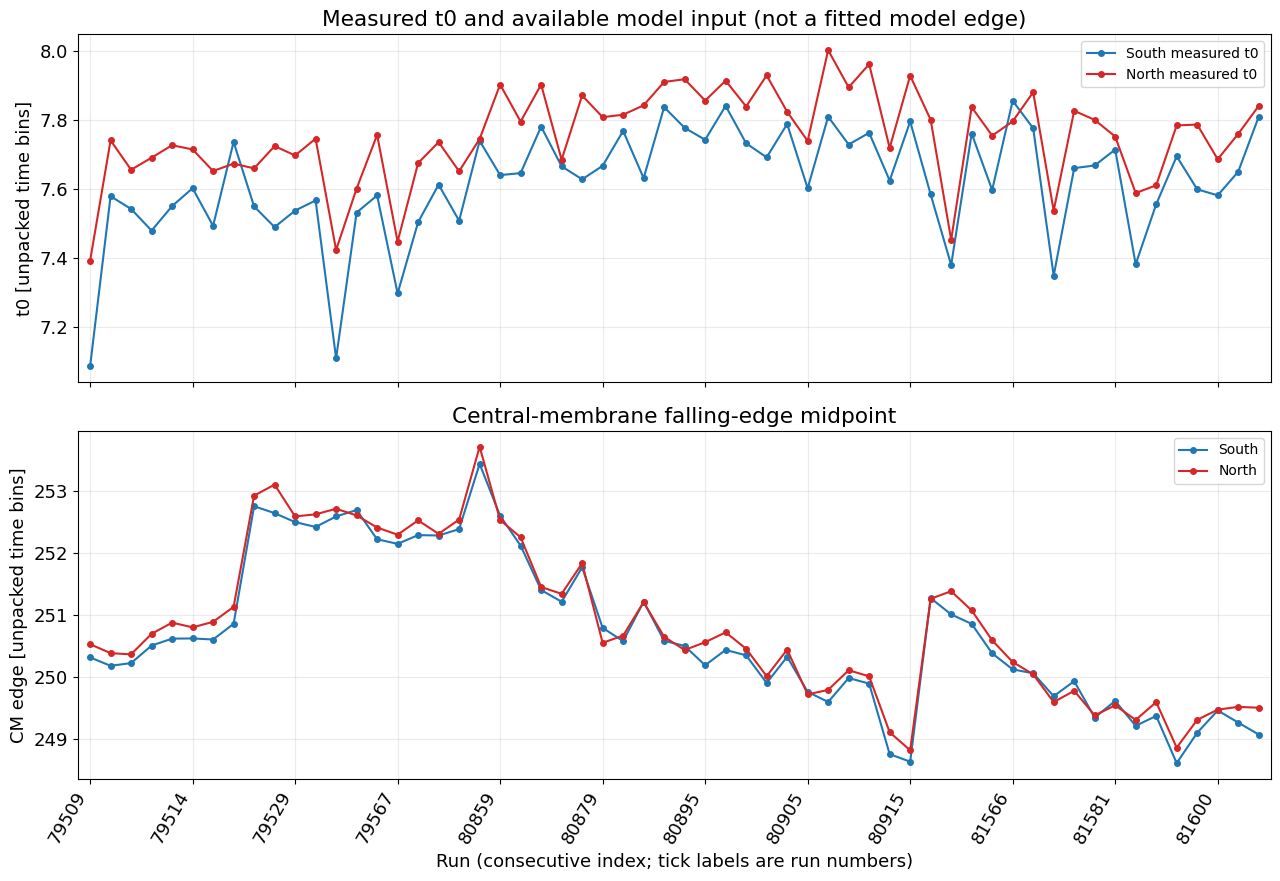

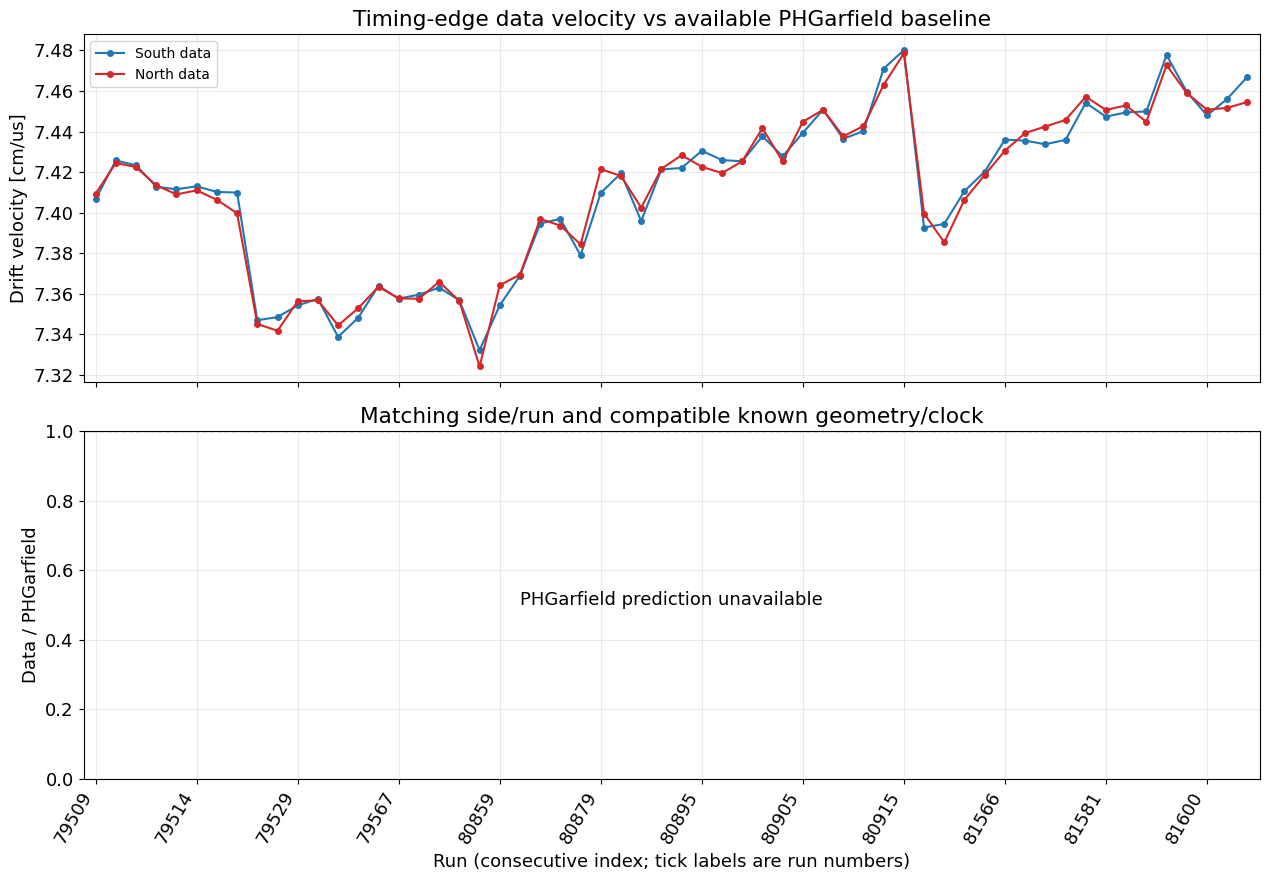

In [13]:
# ============================================================
# t0 / CM for ALL runs; data and PHGarfield velocity comparison
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
for side in ("south", "north"):
    data = DRIFT_SUMMARY[DRIFT_SUMMARY.side == side]
    x = [RUN_INDEX[r] for r in data.run]
    axes[0].plot(x, data.t0_bins, "o-", ms=4, color=COLORS[side], label=f"{SIDE_LABEL[side]} measured t0")
    if np.isfinite(data.configured_t0_bins).any():
        axes[0].plot(x, data.configured_t0_bins, "--", color=COLORS[side], label=f"{SIDE_LABEL[side]} PHGarfield configured t0")
    axes[1].plot(x, data.cm_bins, "o-", ms=4, color=COLORS[side], label=SIDE_LABEL[side])
axes[0].set(ylabel="t0 [unpacked time bins]", title="Measured t0 and available model input (not a fitted model edge)")
axes[1].set(ylabel="CM edge [unpacked time bins]", title="Central-membrane falling-edge midpoint")
for ax in axes:
    legend_if_any(ax, fontsize=10)
run_axis(axes[-1])
finish(fig,"timing_t0_cm_all_runs")

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
for side in ("south", "north"):
    data = DRIFT_SUMMARY[DRIFT_SUMMARY.side == side]
    x = [RUN_INDEX[r] for r in data.run]
    axes[0].plot(x,data.v_data_cm_us,"o-",ms=4,color=COLORS[side],label=f"{SIDE_LABEL[side]} data")
    if np.isfinite(data.v_phg_cm_us).any():
        axes[0].plot(x,data.v_phg_cm_us,"s--",ms=4,color=COLORS[side],label=f"{SIDE_LABEL[side]} PHGarfield baseline (see source table)")
        axes[1].plot(x,data.data_over_phg,"o-",ms=4,color=COLORS[side],label=SIDE_LABEL[side])
axes[0].set(ylabel="Drift velocity [cm/us]",title="Timing-edge data velocity vs available PHGarfield baseline")
axes[1].set(ylabel="Data / PHGarfield",title="Matching side/run and compatible known geometry/clock")
axes[1].axhline(1,color="gray",ls="--",lw=1)
if not np.isfinite(DRIFT_SUMMARY.v_phg_cm_us).any():
    axes[1].text(.5,.5,"PHGarfield prediction unavailable",transform=axes[1].transAxes,ha="center")
for ax in axes:
    legend_if_any(ax,fontsize=10)
run_axis(axes[-1])
finish(fig,"drift_velocity_data_phgarfield_all_runs")

## rDCA change versus GEM current and k_eff

The default y observable is the **change of the odd cos(phi) coefficient** from
the reference. It avoids averaging away a signed distortion. Change `METRIC`
to `odd_sin1`, `odd_offset`, etc. to inspect other components.

Only actual recorded conditions are plotted. For legacy PCA-z populations, only
run-level conditions are accepted. An optional straight-line fit is descriptive;
it does not determine a new k_eff without a controlled response study. That fit
excludes the reference and includes the common reference variance in its covariance
matrix. Other run-to-run systematic correlations are not available.

No accepted harmonic/reference pairs: response plots remain empty.


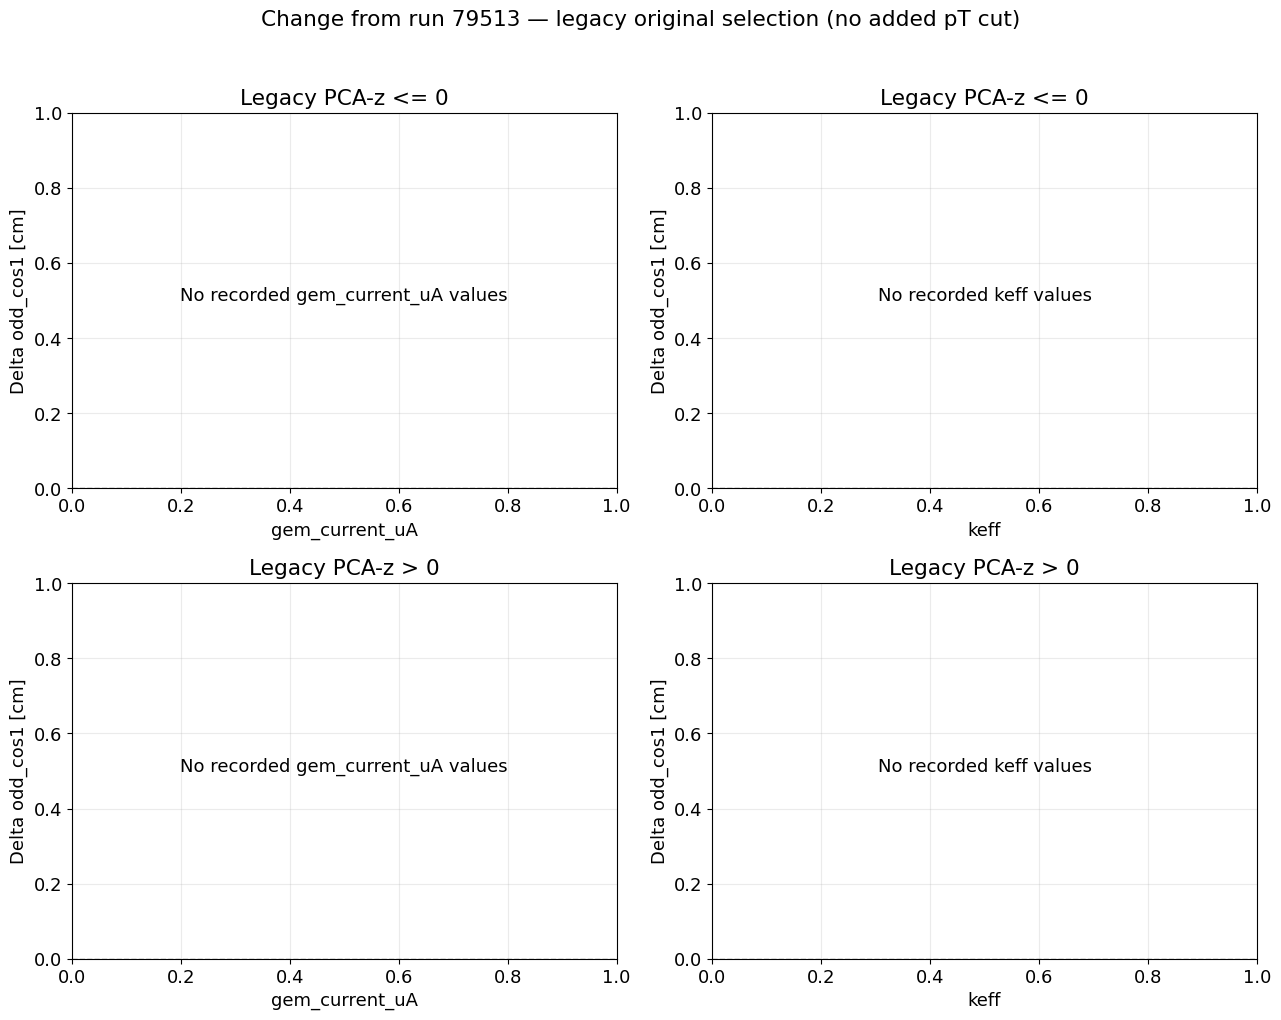

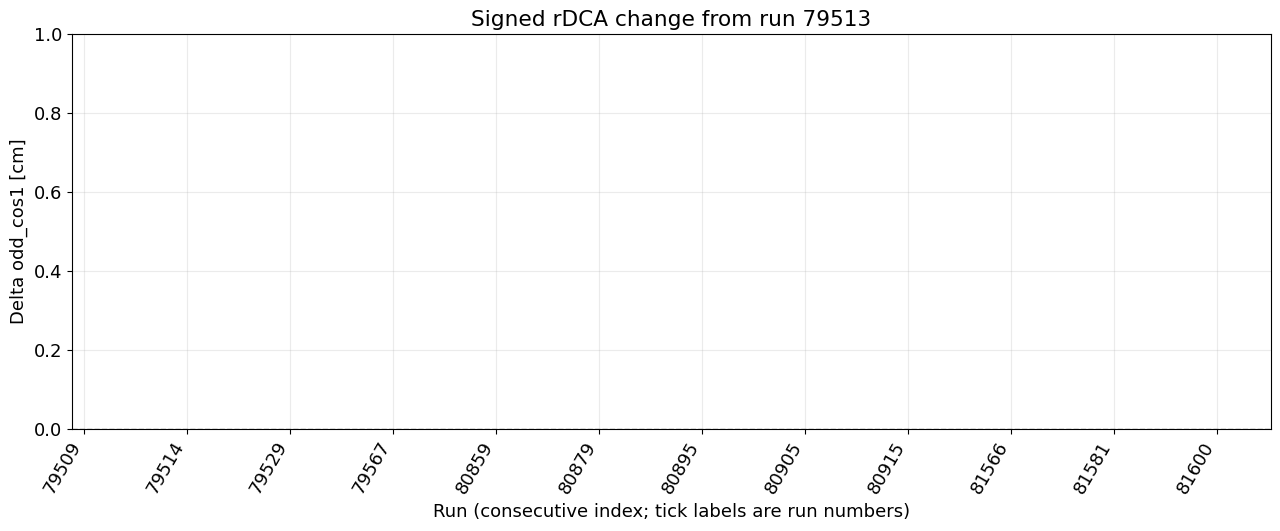

In [14]:
# ============================================================
# Distortion-response scatter plots — missing metadata is explicit
# ============================================================
METRIC = "odd_cos1"
scatter_rows = []
parameter = PARAMETERS.index(METRIC.removeprefix("odd_").removeprefix("even_"))
component = "odd" if METRIC.startswith("odd_") else "even"
for population in POPULATIONS:
    ref = harmonic_fit(REFERENCE_RUN, PRIMARY_PT, population, component)
    for run in AVAILABLE_RUNS:
        fit = harmonic_fit(run, PRIMARY_PT, population, component)
        if ref is None or fit is None:
            continue
        self_ref = run == REFERENCE_RUN
        value = fit["value"][parameter] - ref["value"][parameter]
        own_var = max(0.,fit["covariance"][parameter,parameter])
        ref_var = max(0.,ref["covariance"][parameter,parameter])
        scatter_rows.append(dict(run=run,population=population_label(population),population_key=population,
                                 delta_rdca_cm=value,error_cm=0. if self_ref else np.sqrt(own_var+ref_var),
                                 sample_variance_cm2=own_var,reference_variance_cm2=ref_var,
                                 gem_current=condition(run,population,GEM_COLUMN),keff=condition(run,population,KEFF_COLUMN)))
SCATTER_SUMMARY = pd.DataFrame(scatter_rows, columns=["run","population","population_key","delta_rdca_cm","error_cm","sample_variance_cm2","reference_variance_cm2","gem_current","keff"])
for column in ("run", "delta_rdca_cm", "error_cm", "sample_variance_cm2", "reference_variance_cm2", "gem_current", "keff"):
    SCATTER_SUMMARY[column] = pd.to_numeric(SCATTER_SUMMARY[column], errors="coerce")
if SCATTER_SUMMARY.empty:
    print("No accepted harmonic/reference pairs: response plots remain empty.")
fig, axes = plt.subplots(2,2,figsize=(13,10))
for i,population in enumerate(POPULATIONS):
    for j,(field,label) in enumerate((("gem_current",GEM_COLUMN),("keff",KEFF_COLUMN))):
        ax=axes[i,j]
        data=SCATTER_SUMMARY[(SCATTER_SUMMARY.population_key==population)&np.isfinite(SCATTER_SUMMARY[field])]
        if data.empty:
            ax.text(.5,.5,f"No recorded {label} values",ha="center",transform=ax.transAxes)
        else:
            ax.errorbar(data[field],data.delta_rdca_cm,yerr=data.error_cm,fmt="o",ms=5,color=COLORS[population])
            if len(data)<=12:
                for row in data.itertuples():
                    ax.annotate(str(row.run),(getattr(row,field),row.delta_rdca_cm),xytext=(4,4),textcoords="offset points",fontsize=8)
            sample=data[data.run!=REFERENCE_RUN].copy()
            if FIT_RESPONSE and len(sample)>=4 and sample[field].nunique()>=3 and (sample.sample_variance_cm2>0).all():
                x=sample[field].to_numpy(float);y=sample.delta_rdca_cm.to_numpy(float)
                design=np.column_stack([np.ones(len(x)),x])
                covariance=np.diag(sample.sample_variance_cm2.to_numpy(float))+sample.reference_variance_cm2.iloc[0]*np.ones((len(x),len(x)))
                inverse=np.linalg.inv(covariance)
                normal=design.T@inverse@design
                if np.linalg.matrix_rank(normal)==2:
                    parameter_covariance=np.linalg.inv(normal)
                    beta=parameter_covariance@design.T@inverse@y
                    xx=np.linspace(x.min(),x.max(),100)
                    ax.plot(xx,beta[0]+beta[1]*xx,"--",color="black",label=f"descriptive slope {beta[1]:.3g} +/- {np.sqrt(parameter_covariance[1,1]):.2g}")
                    legend_if_any(ax,fontsize=9)
        ax.set(xlabel=label,ylabel=f"Delta {METRIC} [cm]",title=population_label(population))
        ax.axhline(0,color="gray",ls="--",lw=1)
fig.suptitle(f"Change from run {REFERENCE_RUN} — {pt_label(PRIMARY_PT)}",y=1.02)
finish(fig,"rdca_difference_vs_current_keff")

# The same signed reference change as a run trend, even without conditions tables.
fig, ax = plt.subplots(figsize=(13,5.5))
for population in POPULATIONS:
    data = SCATTER_SUMMARY[SCATTER_SUMMARY.population_key == population]
    if not data.empty:
        ax.errorbar([RUN_INDEX[r] for r in data.run], data.delta_rdca_cm, yerr=data.error_cm,
                    fmt="o-", ms=4, lw=1, color=COLORS[population], label=population_label(population))
ax.axhline(0,color="gray",ls="--",lw=1)
ax.set(ylabel=f"Delta {METRIC} [cm]",title=f"Signed rDCA change from run {REFERENCE_RUN}")
run_axis(ax)
legend_if_any(ax,fontsize=10)
finish(fig,"rdca_reference_change_all_runs")

## Export the small tables

CSV tables retain units and statistical errors where available. Keep the input
ROOT file for full 1D profiles, masks and fit covariance. These outputs support
the later offline response study; no new detector correction is applied here.

In [15]:
# ============================================================
# Small offline outputs
# ============================================================
FIT_SUMMARY.to_csv(OUTPUT_DIR/"rdca_harmonic_summary.csv",index=False)
DRIFT_SUMMARY.to_csv(OUTPUT_DIR/"timing_drift_summary.csv",index=False)
CONDITIONS_AVAILABLE.to_csv(OUTPUT_DIR/"conditions_availability.csv",index=False)
SCATTER_SUMMARY.to_csv(OUTPUT_DIR/"rdca_response_points.csv",index=False)
print("Plots and small tables:",OUTPUT_DIR.resolve())
print("Input group:",GROUP,"; runs:",len(AVAILABLE_RUNS),"; reference:",REFERENCE_RUN)
print("DCA populations:",[population_label(p) for p in POPULATIONS])
print("Do not convert an observable ratio directly to a k_eff ratio; calibrate the response first.")

Plots and small tables: /home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/spy/tpc_qa_plots
Input group: run3pp/ana581_2026p005_v001 ; runs: 58 ; reference: 79513
DCA populations: ['Legacy PCA-z <= 0', 'Legacy PCA-z > 0']
Do not convert an observable ratio directly to a k_eff ratio; calibrate the response first.


## Next QA pass

Keep this current 10-segment summary. A later pass can include O+O and Au+Au;
choose one production group at a time using `GROUP`. Directory names alone do
not certify collision species; retain the actual run classification in the conditions table.

Record the **actual applied** `keff` and measured `gem_current_uA`, separately
for each physical side when appropriate. Retain their source, units and segment/time
coverage; for time-varying values also retain their spread or range. A full-run average
may not match the first ten selected segments. Current and k_eff are distinct quantities.
Do not substitute a nominal field setting or infer either value from an rDCA histogram.
A historical CDB lookup should be labeled as a reconstructed conditions snapshot if
it cannot certify the exact payload used during reconstruction.

Validation: all plotting cells were executed with real ROOT synthetic legacy and new-QA
inputs. Missing conditions, stored/supplied PHGarfield predictions, selected pT/eta
panels and the optional descriptive response fit were exercised. Synthetic tests
establish code behavior; real production results still need inspection.
